In [2]:
import pandas as pd
import numpy as np

al = pd.read_csv("export_alimconfiance.csv", sep=";", dtype=str)
al["SIRET"].nunique(),al["SIRET"].value_counts().describe()

(64575,
 count    64575.000000
 mean         1.101851
 std          0.496607
 min          1.000000
 25%          1.000000
 50%          1.000000
 75%          1.000000
 max         18.000000
 Name: count, dtype: float64)

Le jeu contient 71 152 inspections pour 64 575 établissements distincts, soit 1,10 inspection par établissement en moyenne. La médiane et les quartiles valent 1 : au moins 75% des établissements ne sont inspectés qu’une seule fois. Seules 6 577 inspections (9,2%) sont des inspections répétées, et le maximum est de 18 pour un établissement. Aucun établissement n’est donc fortement surreprésenté.
On va tout de même pour minimiser les risques séparé les données de test et d'entrainement par SIRET afin d'evité qu'un etablissement soit present des deux cotés.

In [3]:
al["Date_inspection"].head()
al["Date_inspection"] = pd.to_datetime(al["Date_inspection"], utc=True)

Nous sommes face à un format de date stantard, donc la conversion se fera sans soucis. L’heure des observations semble indiquer que le jeu semble ne stocke que des jours. 

<Axes: title={'center': 'Inspections par mois'}, xlabel='Date_inspection'>

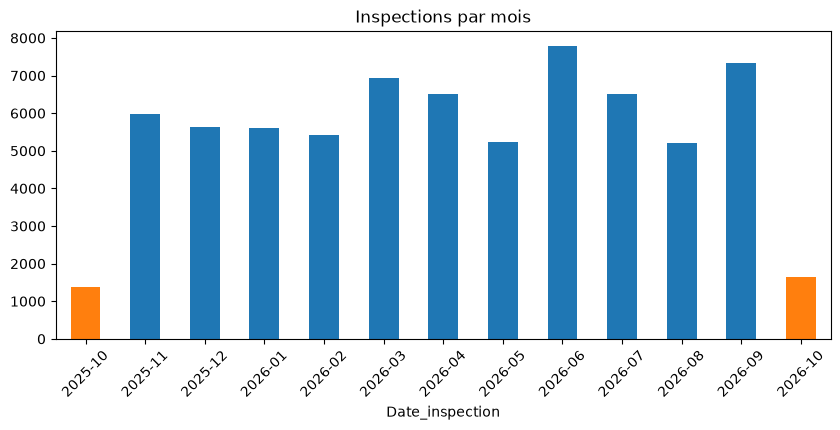

In [4]:
import matplotlib.pyplot as plt

inspection = al["Date_inspection"].dt.strftime("%Y-%m").value_counts().sort_index()
c = ["tab:orange" if i in ["2025-10", "2026-10"] else "tab:blue" for i in inspection.index]

inspection.plot.bar(color=c, figsize=(10, 4), rot=45, title="Inspections par mois")


In [5]:
al["Date_inspection"].dt.strftime("%Y-%m").value_counts().sort_index().describe()

count      13.000000
mean     5473.230769
std      1934.430586
min      1375.000000
25%      5235.000000
50%      5632.000000
75%      6506.000000
max      7800.000000
Name: count, dtype: float64

## Répartition des inspections par mois

La période couverte est continue : les 13 mois  totalisent 71 152 inspections.

Deux mois sont **partiels** et ne sont pas comparables aux autres :
- octobre 2025 : 1 375 inspections (à partir du 25 octobre seulement),
- octobre 2026 : 1 654 inspections (jusqu'au 23 octobre seulement).

Sur les 11 mois complets (novembre 2025 -> septembre 2026), le volume est globalement stable : moyenne environ 6 193 inspections par mois, minimum 5 213 (août 2026), maximum 7 800 (juin 2026). On note un pic en juin 2026, dont la cause n'est pas déterminée à ce stade.

Remarque : octobre 2026 ne compte qu'environ 72 inspections par jour, contre environ 200 par jour en octobre 2025, ce n'est donc pas seulement un effet de mois tronqué. L'hypothèse d'un délai de publication des résultats reste à vérifier.

In [6]:
cols = ["Evaluation_globale", "Type_suite", "Conclusion_suite", "APP_Code_synthese_eval_sanit",
        "Agrement", "Libelle_agrement", "Etat_autorisation",
        "Destination", "Lieu",
        "Code_commune", "Libelle_commune", "Code_postal", "com_name", "dep_name", "reg_name"]

defavorable = al["Synthese_eval_sanit"].isin(["A améliorer", "A corriger de manière urgente"])

for c in cols:
    print(f"\n{c} : {al[c].nunique()} modalités, {al[c].isna().mean():.1%} NaN")
    if al[c].nunique() <= 15:
        print(pd.crosstab(al["Synthese_eval_sanit"], al[c], dropna=False))
    else:
        print(al[c].value_counts().head(5))
        tmp = al[[c]].copy()
        tmp["d"] = defavorable
        tmp = tmp.dropna()
        print(tmp.groupby(c)["d"].agg(["mean", "size"]).query("size >= 30").sort_values("mean", ascending=False).head(5))

ed = pd.to_datetime(al["Date_edition_RI"], utc=True)
print("\nDate_edition_RI :", (ed >= al["Date_inspection"]).value_counts().to_dict())

print("\nRedondance avec com_code :")
for c in ["Code_commune", "Libelle_commune", "Code_postal", "com_name", "dep_name", "reg_name"]:
    print(c, f"{(al.groupby('com_code')[c].nunique() > 1).mean():.2%}")


Evaluation_globale : 8 modalités, 0.0% NaN
Evaluation_globale             A - Conforme  B - Non conformité mineure  \
Synthese_eval_sanit                                                       
A améliorer                               0                           0   
A corriger de manière urgente             0                           0   
Satisfaisant                              4                         119   
Très satisfaisant                       353                          21   
NaN                                       0                           0   

Evaluation_globale             C - Non conformité moyenne  \
Synthese_eval_sanit                                         
A améliorer                                             9   
A corriger de manière urgente                           0   
Satisfaisant                                            5   
Très satisfaisant                                       0   
NaN                                                     0   

Ev

### Bilan des colonnes suspecte vérifiées

Chaque colonne suspecte a été croisée avec `Synthese_eval_sanit` (crosstab complet si ≤15 modalités, sinon cardinalité + top 5 des modalités les plus défavorables avec ≥30 inspections), ou comparée à `com_code` pour les colonnes géographiques.

**Fuite de cible (à supprimer)**
- `Evaluation_globale` : "insuffisante" : 98% "A améliorer", "urgence" : 94% "A corriger", "satisfaisante"/"conforme" : 100% favorables.
- `APP_Code_synthese_eval_sanit` : crosstab strictement 1-à-1 avec la cible (code 1–4).
- `Type_suite` : "Mise en demeure" (4 104) : 99% "A améliorer", "Décision" (323) : 100% "A corriger", NaN (21 319) : 100% favorable.
- `Conclusion_suite` : 100% des "A corriger" ont une conclusion non nulle, contre 2% des "A améliorer".

**Fuite temporelle (à supprimer)**
- `Date_edition_RI` : postérieure à `Date_inspection` dans 99,87% des cas

**Redondances (à supprimer)**
- `Agrement` (6 199 modalités, 89% NaN) : transformé en binaire pour savoir si present ou non.
- `Libelle_agrement` (119 modalités) et `Etat_autorisation` (228 modalités) : versions granulaires du même champ, mêmes 7 858 lignes non nulles.
- `Code_commune`, `Libelle_commune`, `Code_postal` : 11 894 à 5 889 modalités, redondants avec `com_code` à ~95% (divergence limitée aux arrondissements Paris/Lyon/Marseille).
- `com_name`, `dep_name`, `reg_name` : libellés entièrement déterminés par `com_code` (0% de divergence). `dep_name` et `reg_name` seront reconstructibles en S3 depuis `com_code` pour les graphiques par département/région.

**Colonnes trop fragmentées ou trop creuses (à supprimer)**
- `Destination` : 516 modalités, 18,7% NaN. Le top 5 des modalités les plus défavorables ne dépasse pas 15%.
- `Lieu` : 46 modalités, 71% de NaN. Signal faible (max 15,3% sur 137 inspections), recoupé par `Type_activite`.

**Conclusion :** suppression de 14 colonnes au total + transformation d'`Agrement` en binaire. `SIRET` et `com_code` sont conservés (clé de split et clé de jointure).

In [7]:
reste = ["Date_de_cessation_BDNU", "geo_mobile", "Procede", "Denree", "Adresse_3_UA",
         "lieu_intervention", "lieu_intervention_adresse", "lieu_intervention_codepostal", "lieu_intervention_ville",
         "Raison_sociale", "Libelle_etablissement", "APP_Libelle_etablissement",
         "APP_ID_regroupement_etablissement", "APP_Libelle_regroupement_etablissement",
         "Code_UA", "Adresse_1_UA", "Adresse_2_UA", "Adresse_activite", "filtre",
         "Contexte_inspection", "Date_extraction", "Numero_inspection",
         "geores", "geo_ban", "geo_resytal", "Localite",
         "Secteur_activite", "ods_type_activite", "APP_Libelle_activite_etablissement",
         "Type_activite", "#Enseigne"]

for c in reste:
    print(f"\n{c} : {al[c].nunique()} modalités, {al[c].isna().mean():.1%} NaN")
    if al[c].nunique() <= 15:
        print(pd.crosstab(al["Synthese_eval_sanit"], al[c], dropna=False))
    else:
        print(al[c].value_counts().head(5))
        tmp = al[[c]].copy()
        tmp["d"] = defavorable
        tmp = tmp.dropna()
        print(tmp.groupby(c)["d"].agg(["mean", "size"]).query("size >= 30").sort_values("mean", ascending=False).head(5))


Date_de_cessation_BDNU : 2 modalités, 100.0% NaN
Date_de_cessation_BDNU         01/11/2026 00:00:00  31/10/2026 00:00:00    NaN
Synthese_eval_sanit                                                           
A améliorer                                      0                    0   4184
A corriger de manière urgente                    0                    0    339
Satisfaisant                                     1                    1  49507
Très satisfaisant                                0                    0  17119
NaN                                              0                    0      1

geo_mobile : 650 modalités, 98.4% NaN
geo_mobile
43.213185, 2.351732    14
41.919799, 8.738296    14
45.460969, 4.764267    11
45.733277, 4.012073     9
43.662827, 1.349878     9
Name: count, dtype: int64
Empty DataFrame
Columns: [mean, size]
Index: []

Procede : 1200 modalités, 97.3% NaN
Procede
SIA 2026                          33
FOIRE DE PARIS 2026               32
Marché public de Grignan

### Nettoyage final : 24 colonnes supprimées, 7 conservées

**Colonnes gardées car elles portent un signal connu avant l'inspection**
- `Contexte_inspection` (6 modalités) : le taux de défavorable varie beaucoup selon le contexte - Re-contrôle 1,5%, Programmation 5,9%, Inspection ciblée 19%, Plainte 20%, TIAC 18,6%. Comme le contexte est connu avant le contrôle, ce n'est pas une fuite.
- `Secteur_activite` (5) et `ods_type_activite` (7) : catégories réglementaires, propres.
- `APP_Libelle_regroupement_etablissement` (2) : Boutique 6,7% de défavorable contre Supermarché/Hypermarché 2,9%. Attribut structurel de l'établissement, pas une fuite.
- `Type_activite` (55) et `APP_Libelle_activite_etablissement` (216) : à regrouper en "activité rare" à l'étape 3.
- `#Enseigne` : à regrouper en top 20 + "autre" / "inconnue".

**Colonnes supprimées**
- Presque vides (≥87% de NaN) : `Date_de_cessation_BDNU` (100%), `geo_mobile` (98,4%), `Procede` (97,3%), les 4 `lieu_intervention*` (97–98%), `Denree` (92,5%), `Adresse_3_UA` (90,6%), `Adresse_1_UA` (87,7%), `geo_resytal` (81,6%). Les rares valeurs non nulles correspondent à des foires ou marchés ponctuels ("FOIRE DE PARIS 2026", "SIA 2026") : aucun intérêt prédictif général.
- Identifiants ou adresses : `Raison_sociale`, `Libelle_etablissement`, `APP_Libelle_etablissement`, `Code_UA`, `Adresse_2_UA`, `Adresse_activite`, `Numero_inspection`, `Localite`.
- Redondants ou constants : `geores` et `geo_ban` (coordonnées GPS déjà couvertes par `com_code`), `Date_extraction` (une seule valeur), `filtre` (recoupe `Type_activite` et `Secteur_activite`), `APP_ID_regroupement_etablissement` (doublon de`APP_Libelle_regroupement_etablissement`).

## Nettoyage des colonnes et de la ligne sans cible

Trois étapes : suppression des 16 colonnes identifiées (fuites, redondances,
fragmentations), puis des 24 colonnes restantes (presque vides, identifiants, adresses,
redondances), enfin de la ligne sans cible. `SIRET` et `com_code` sont conservés
(clé de split, clé de jointure).

In [8]:
a_supprimer = ["Evaluation_globale", "Type_suite", "Conclusion_suite",
               "Date_edition_RI", "APP_Code_synthese_eval_sanit",
               "Libelle_agrement", "Etat_autorisation",
               "Destination", "Lieu",
               "Code_commune", "Libelle_commune", "Code_postal",
               "com_name", "dep_name", "reg_name"]

al["Agrement"] = al["Agrement"].notna().astype(int)

print("avant :", al.shape)
al = al.drop(columns=a_supprimer)
print("après :", al.shape)

avant : (71152, 53)
après : (71152, 38)


In [9]:
autres = ["Date_de_cessation_BDNU", "geo_mobile", "Procede", "Denree", "Adresse_3_UA",
          "lieu_intervention", "lieu_intervention_adresse", "lieu_intervention_codepostal", "lieu_intervention_ville",
          "Raison_sociale", "Libelle_etablissement", "APP_Libelle_etablissement", "Code_UA",
          "Adresse_1_UA", "Adresse_2_UA", "Adresse_activite", "Numero_inspection", "Localite",
          "geores", "geo_ban", "geo_resytal", "Date_extraction", "filtre",
          "APP_ID_regroupement_etablissement"]

print("avant :", al.shape)
al = al.drop(columns=autres)
print("après :", al.shape)
print(list(al.columns))

avant : (71152, 38)
après : (71152, 14)
['APP_Libelle_activite_etablissement', 'Synthese_eval_sanit', 'Date_inspection', 'Agrement', 'Contexte_inspection', '#Enseigne', 'SIRET', 'Type_activite', 'APP_Libelle_regroupement_etablissement', 'Secteur_activite', 'ods_type_activite', 'reg_code', 'dep_code', 'com_code']


In [10]:
print("avant :", al.shape)
al = al[al["Synthese_eval_sanit"].notna()].copy()
print("après :", al.shape)

avant : (71152, 14)
après : (71151, 14)


## Création des variables dérivées

`code_synthese` reprend les 4 niveaux de `Synthese_eval_sanit` (1 à 4). La cible binaire
`defavorable` vaut 1 pour "A améliorer" et "A corriger de manière urgente" (codes 3 et 4),
0 sinon. On ajoute ensuite année, mois, jour de semaine, enseigne regroupée et activité
regroupée.

In [11]:
mapping = {
    "Très satisfaisant": 1,
    "Satisfaisant": 2,
    "A améliorer": 3,
    "A corriger de manière urgente": 4,
}
al["code_synthese"] = al["Synthese_eval_sanit"].map(mapping)
al["defavorable"] = al["code_synthese"].isin([3, 4]).astype(int)

print(al["code_synthese"].value_counts().sort_index())
print("\ndefavorable :", al["defavorable"].sum(), f"({al['defavorable'].mean():.1%})")

code_synthese
1    17119
2    49509
3     4184
4      339
Name: count, dtype: int64

defavorable : 4523 (6.4%)


In [12]:
al["Date_inspection"] = pd.to_datetime(al["Date_inspection"])

al["annee"] = al["Date_inspection"].dt.year
al["mois"] = al["Date_inspection"].dt.month
al["jour_semaine"] = al["Date_inspection"].dt.dayofweek  # 0 = lundi

print(al["annee"].value_counts().sort_index())
print("mois  :", sorted(al["mois"].unique().tolist()))
print("jour  :", sorted(al["jour_semaine"].unique().tolist()))

annee
2025    12978
2026    58173
Name: count, dtype: int64
mois  : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
jour  : [0, 1, 2, 3, 4, 5, 6]


## Enseigne : variable à 3 niveaux

`#Enseigne` compte 50 952 modalités pour 71 151 inspections : la plupart des valeurs sont
des noms propres d'établissement uniques. Une binaire %avec / sans enseigne" donnerait
98,7% de 1 et n'apprendrait rien au modèle.

On crée donc une variable `enseigne` à 3 niveaux :
- 0 : pas d'enseigne (valeur manquante ou %Etablissement sans enseigne") ;
- 1 : enseigne renseignée mais rare (hors top 20) ;
- 2 : enseigne parmi les 20 plus fréquentes (chaînes et structures connues).

In [13]:
ens = al["#Enseigne"]
sans = ens.isna() | (ens == "Etablissement sans enseigne")
top20 = ens.value_counts().head(20).index

al["enseigne"] = np.where(sans, 0, np.where(ens.isin(top20), 2, 1))
al = al.drop(columns=["#Enseigne"])

print(al["enseigne"].value_counts().sort_index())

enseigne
0     3900
1    63752
2     3499
Name: count, dtype: int64


In [14]:
act = al["Type_activite"].fillna("inconnue")
top = act.value_counts()
al["activite"] = act.where(act.isin(top[top >= 100].index), "autre")

print(al["activite"].value_counts())

activite
Restauration commerciale                                        33068
Métier de bouche                                                14629
Commerce alimentaire (autres que prod.fermier/métier bouche)     7614
Restauration collective, cuisine centrale et traiteur agréé      6946
Producteur fermier                                               1306
Transformation de lait ou produits laitiers                      1108
Transformation de produits carnés                                 925
autre                                                             844
Purification/Expédition de coquillages                            675
Transport de denrées alimentaires                                 659
Chaîne d'abattage de volaille/lagomorphe/petit gibier             608
Découpe de viande de boucherie                                    550
Centre d'emballage des oeufs                                      423
VH, VSM, préparation viandes boucherie                            335
Entreposage

In [15]:
al = al.drop(columns=["Type_activite", "APP_Libelle_activite_etablissement",
                      "Synthese_eval_sanit", "dep_code", "reg_code"])
print(al.shape)
print(list(al.columns))

(71151, 15)
['Date_inspection', 'Agrement', 'Contexte_inspection', 'SIRET', 'APP_Libelle_regroupement_etablissement', 'Secteur_activite', 'ods_type_activite', 'com_code', 'code_synthese', 'defavorable', 'annee', 'mois', 'jour_semaine', 'enseigne', 'activite']


## Ajout des indicateurs communaux

Pour le modèle B, on veut ajouter des informations sur la commune de l'établissement : le revenu médian (`MED_SL`) et le taux de pauvreté (`PR_MD60`) de Filosofi 2023, et la population (`PMUN`) du fichier des populations 2023. Le modèle A n'aura pas ces colonnes, ce qui permettra de voir si le contexte local apporte quelque chose.

La jointure se fait sur le code commune `com_code`. Il faut donc d'abord que chaque fichier ait une seule ligne par commune.

Une limite à garder en tête : ces indicateurs décrivent la commune, pas l'établissement. Deux restaurants de la même commune auront exactement les mêmes valeurs.

### Filosofi

Le fichier est en format long : une ligne par zone et par indicateur. On garde seulement le niveau `COM` et les deux indicateurs qui nous intéressent, puis on pivote pour avoir une ligne par commune. Les valeurs confidentielles ne sont pas des nombres, elles passent en `NaN` avec `errors="coerce"`.

On lit `GEO` en texte, sinon les codes comme `01001` perdent leur zéro et ne correspondent plus à `com_code`.

In [16]:
filo = pd.read_csv("FILOSOFI_CC_csv/DS_FILOSOFI_CC_2023_data.csv", sep=";", dtype={"GEO": str})
filo = filo[(filo["GEO_OBJECT"] == "COM") & (filo["FILOSOFI_MEASURE"].isin(["MED_SL", "PR_MD60"]))].copy()
filo["OBS_VALUE"] = pd.to_numeric(filo["OBS_VALUE"], errors="coerce")

filo_pivot = (filo.pivot_table(index="GEO", columns="FILOSOFI_MEASURE",
                               values="OBS_VALUE", aggfunc="first")
              .rename(columns={"MED_SL": "revenu_median", "PR_MD60": "taux_pauvrete"})
              .reset_index()
              .rename(columns={"GEO": "com_code"}))

print(filo_pivot.shape)
print("com_code unique :", filo_pivot["com_code"].is_unique)
print("longueurs :", filo_pivot["com_code"].str.len().value_counts().to_dict())
print(filo_pivot[["revenu_median", "taux_pauvrete"]].notna().sum())

(30794, 3)
com_code unique : True
longueurs : {5: 30794}
FILOSOFI_MEASURE
revenu_median    30794
taux_pauvrete     5242
dtype: int64


On obtient 30 794 communes, avec un `com_code` unique de 5 caractères. Le revenu médian est renseigné partout, mais le taux de pauvreté seulement pour 5 242 communes : il n'est pas diffusé pour les petites communes (secret statistique).

Le niveau `COM` contenait 34 768 communes, donc 3 974 ont disparu au pivot. Elles n'avaient ni revenu ni taux de pauvreté, et `pivot_table` supprime les lignes entièrement vides. Ce n'est pas grave, elles auront des `NaN` après la jointure de toute façon.

### Population

Dans Alim'confiance, Paris, Lyon et Marseille ont le code de la commune entière (75056, 69123, 13055), alors que le fichier des populations ne donne que les arrondissements. Sans correction, ces trois villes n'auraient pas de population. On additionne donc leurs arrondissements, repérés par le début de leur code (751, 6938 et 132). On affiche le nombre d'arrondissements trouvés pour vérifier : il doit être de 20, 9 et 16.

In [17]:
pop = pd.read_csv("ensemble/donnees_communes.csv", sep=";", dtype={"COM": str})
pop["PMUN"] = pd.to_numeric(pop["PMUN"], errors="coerce")

arr = {"75056": "751", "69123": "6938", "13055": "132"}
agg = []
for code, prefixe in arr.items():
    masque = pop["COM"].str.startswith(prefixe)
    print(code, ":", masque.sum(), "arrondissements")
    agg.append({"COM": code, "PMUN": pop.loc[masque, "PMUN"].sum()})

pop_clean = (pd.concat([pop[["COM", "PMUN"]], pd.DataFrame(agg)], ignore_index=True)
             .rename(columns={"COM": "com_code", "PMUN": "population"}))

print(pop_clean[pop_clean["com_code"].isin(arr)])
print("com_code unique :", pop_clean["com_code"].is_unique)

75056 : 20 arrondissements
69123 : 9 arrondissements
13055 : 16 arrondissements
      com_code  population
34900    75056     2103778
34901    69123      519127
34902    13055      886040
com_code unique : True


### Jointure

On fait une jointure gauche sur `com_code` pour garder toutes les inspections, même celles dont la commune n'a pas d'indicateur (outre-mer, petites communes). Elles auront des `NaN`, qu'on traitera en S4. Une jointure interne aurait supprimé ces lignes et favorisé les grandes communes.

Comme chaque table communale a une ligne par commune, le nombre de lignes ne doit pas changer : on le vérifie avec un `assert`.

In [18]:
n = len(al)

al = (al.drop(columns=["revenu_median", "taux_pauvrete", "population"], errors="ignore")
        .merge(filo_pivot, on="com_code", how="left")
        .merge(pop_clean, on="com_code", how="left"))

assert len(al) == n
print(al.shape)

(71151, 18)


### Vérification de la jointure

On regarde la part de lignes qui ont reçu chaque indicateur, sur celles qui ont un `com_code` (sans code commune la jointure ne pouvait rien faire, et ça vient d'Alim'confiance). On teste aussi deux explications pour les valeurs manquantes : le revenu manque surtout en outre-mer (971, 972, 973, 976, hors Filosofi), et le taux de pauvreté dans les petites communes.

In [19]:
avec_code = al[al["com_code"].notna()]
print(len(avec_code), "lignes avec com_code sur", len(al))
print(avec_code[["revenu_median", "taux_pauvrete", "population"]].notna().mean().round(3))

# revenu : est-ce que ça vient de l'outre-mer ?
drom = avec_code["com_code"].str.startswith(("971", "972", "973", "976"))
print("revenu renseigné hors de ces DROM :", avec_code.loc[~drom, "revenu_median"].notna().mean().round(3))

# taux de pauvreté : est-ce que ce sont des petites communes ?
print(avec_code.groupby(avec_code["taux_pauvrete"].isna())["population"].median())
print(al.shape)

69397 lignes avec com_code sur 71151
revenu_median    0.985
taux_pauvrete    0.801
population       0.998
dtype: float64
revenu renseigné hors de ces DROM : 0.995
taux_pauvrete
False    23559.0
True       986.0
Name: population, dtype: float64
(71151, 18)


## Bilan de la jointure

La jointure garde les 71 151 lignes et ajoute 3 colonnes : on passe de 15 à 18 colonnes. Sur les 69 397 lignes qui ont un `com_code` (97,5%) :
- `revenu_median` est renseigné pour 98,5% des lignes (99,6% hors outre-mer) ;
- `taux_pauvrete` pour 80,1% (les petites communes sont sous secret statistique) ;
- `population` pour 99,8%.

Les `NaN` ne sont pas aléatoires (petites communes, outre-mer). On les remplacera en S4, avec des valeurs calculées sur le train uniquement. Les 3 variables sont aussi identiques pour tous les établissements d'une même commune.

On passe maintenant à la séparation entre train et test.

## Séparation train / test

Un même établissement peut être inspecté plusieurs fois (18 fois au maximum). Si on coupait au hasard ligne par ligne, certains établissements seraient à la fois dans le train et dans le test, et le score du modèle serait trop optimiste. On sépare donc par `SIRET` : 80% des établissements en train et 20% en test, avec `GroupShuffleSplit` et `random_state=42` pour que ce soit reproductible. Comme la plupart des établissements n'ont qu'une inspection, on devrait rester proche de 80/20 en nombre de lignes.

On fait ce découpage avant de remplacer les valeurs manquantes ou de choisir des paramètres : tout ça se fera sur le train, le test servira seulement à l'évaluation finale.

In [20]:
from sklearn.model_selection import GroupShuffleSplit

print("SIRET manquants :", al["SIRET"].isna().sum())

separation = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(separation.split(al, groups=al["SIRET"].fillna("inconnu")))

train = al.iloc[idx_train].copy()
test = al.iloc[idx_test].copy()
print("train :", train.shape, "| test :", test.shape)

SIRET manquants : 0
train : (56944, 18) | test : (14207, 18)


On vérifie qu'on n'a perdu aucune ligne, qu'aucun `SIRET` n'est présent des deux côtés, et que le taux de défavorable est proche dans les deux jeux (autour de 6,4%).

In [21]:
assert len(train) + len(test) == len(al)

communs = set(train["SIRET"].dropna()) & set(test["SIRET"].dropna())
print("SIRET en commun :", len(communs))
assert len(communs) == 0

print("SIRET distincts : train", train["SIRET"].nunique(), "| test", test["SIRET"].nunique())
print("part des lignes : train", round(len(train) / len(al), 3), "| test", round(len(test) / len(al), 3))
print("taux de défavorable : train", round(train["defavorable"].mean(), 4),
      "| test", round(test["defavorable"].mean(), 4))

SIRET en commun : 0
SIRET distincts : train 51659 | test 12915
part des lignes : train 0.8 | test 0.2
taux de défavorable : train 0.0633 | test 0.0645


### Sauvegarde

On sauvegarde les deux jeux dans `data/` avec toutes les colonnes. `code_synthese` reste dans les fichiers pour les graphiques de la S3, mais elle ne devra pas servir au modèle (c'est la cible en 4 niveaux). Pour relire les fichiers, il faut mettre `dtype=str` pour `SIRET` et `com_code`, sinon les zéros au début des codes communes sont perdus.

In [22]:
import os

os.makedirs("data", exist_ok=True)
train.to_csv("data/train.csv", index=False)
test.to_csv("data/test.csv", index=False)

for nom, jeu in [("train", train), ("test", test)]:
    relu = pd.read_csv(f"data/{nom}.csv", dtype={"SIRET": str, "com_code": str})
    print(nom, relu.shape, jeu.shape)
    assert relu.shape == jeu.shape

print(list(train.columns))

train (56944, 18) (56944, 18)
test (14207, 18) (14207, 18)
['Date_inspection', 'Agrement', 'Contexte_inspection', 'SIRET', 'APP_Libelle_regroupement_etablissement', 'Secteur_activite', 'ods_type_activite', 'com_code', 'code_synthese', 'defavorable', 'annee', 'mois', 'jour_semaine', 'enseigne', 'activite', 'revenu_median', 'taux_pauvrete', 'population']
